# Climate Comfort Index · Dummy Regressor

**36120 Advanced Machine Learning Application** · Assessment Task 2 · Weather Intelligence (Open-Meteo, Sydney)

*Experiment notebook · predicts CCI +1, +2 and +3 days ahead*

This notebook develops the **Dummy Regressor** model for the **Climate Comfort Index (CCI)**: pipeline stages 1-2, using the leakage-audited feature matrix produced by the preprocessing notebook.

### Student details

| | |
|:--|:--|
| **Student name** | Juan Vargas T. |
| **Student ID** | 25945320 |
| **Subject** | 36120 Advanced Machine Learning Application |
| **Assessment** | AT2 · Weather Intelligence |
| **GitHub** | [Sebas102507](https://github.com/Sebas102507) |

## Overview

### Hypothesis

`DummyRegressor(strategy="mean")` ignores the features and predicts the training-set average CCI
for every day and every horizon. It is the correct **null model**: every other CCI experiment,
and both naive baselines, should beat it.

The hypothesis is that **the constant mean is the weakest forecast in the project**, and that
the gap between it and the two naive baselines shows how much current weather (persistence) and
the calendar (climatology) are each worth before any model is fitted.

This notebook is **not a deployment candidate**; it establishes the floor.

### Design

| Choice | Value | Reason |
|:--|:--|:--|
| Algorithm | `DummyRegressor(strategy="mean")` | sklearn's standard regression null model |
| Features | Received, then ignored | The constant does not depend on `X` |
| Scaling | None | A constant is unaffected by feature scale |
| Strategy | One model per horizon (the endpoint returns three values) | Matches the deployed artefact layout |
| Selection | `default_params` only; never tuned or shortlisted | A null model is the floor, not a candidate |
| Objective | validation **mean absolute error (MAE)**, in CCI points (lower is better), averaged over the walk-forward folds | Used for every comparison |

### Where this notebook sits in the pipeline

| Stage | What happens | Where |
|:-:|:--|:--|
| 1–2 | Baselines, ablation and hyperparameter tuning on all features | **This notebook** |
| 3 | Shortlist the best tuned algorithms | Comparison notebook |
| 4 | Feature selection for the shortlist, then a short re-tune | Comparison notebook |
| 5–6 | Choose the champion; refit it on all development data | Comparison notebook |
| 7 | Score the champion once on the test split (2025) | Comparison notebook |
| 8 | Deploy with drift monitoring | Promotion + API |

Every score in this notebook is a **walk-forward cross-validation** average: the development split
(2016–2024) is divided into four expanding-window folds that validate on 2021, 2022, 2023 and 2024
in turn, with the embargo as a gap. A setting therefore has to work across four years, not one. The
test split is never loaded here.

### Workflow

All ten experiment notebooks run the same code from `nucleus_ml.weather.Experiment`, so their results are directly comparable. **Only the model specification in section 1 differs between notebooks.**

| # | Step | Purpose |
|:-:|:--|:--|
| 1 | Model specification | The only algorithm-specific cell |
| 2 | Data and folds | The development split and its walk-forward folds |
| 3 | Baselines | Stage 1: the floor every model must clear |
| 4 | Feature-family ablation | What each block of engineered features contributes |
| 5 | Cross-validated results | The model against its default and the baselines |
| 6 | Feature importance | Which features the model relies on |
| 7 | Generalisation check | Training vs validation performance |
| 8 | Save the experiment bundle | Model, CV results and specification |
| 9 | Conclusions | What to carry into the report |

---
## 0. Setup

Imports, the experiment's identity and the task definition. Everything else comes from the project package.

In [11]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.dummy import DummyRegressor

from nucleus_ml import weather as wx

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.float_format", "{:.3f}".format)

TASK = "comfort_climate"
EXPERIMENT = "cci_dummy_mean"
ALGORITHM = "Dummy Regressor"
VERBOSE = 1  # 0 = results only, 1 = progress + every Optuna trial, 2 = every model fit

task = wx.load_task(TASK)
print(f"{task.target_name} | {ALGORITHM} | {len(task.feature_columns)} features | "
      f"targets: {task.target_columns}")

Climate Comfort Index | Dummy Regressor | 105 features | targets: ['cci_t1', 'cci_t2', 'cci_t3']


---
## 1. Model specification

This is the **only algorithm-specific cell**. It creates the experiment from the estimator class, which the package builds (seeding it and, where requested, scaling the features), so no helper function is needed. It also sets the configuration the model always uses (`default_params`).

The model has a single setting, `strategy="mean"`, which is used as is. The dummy regressor has
no `random_state`, so no seed is passed.

In [12]:
exp = wx.Experiment(
    task,
    name=EXPERIMENT,
    algorithm=ALGORITHM,
    verbose=VERBOSE,
    estimator=DummyRegressor,
    default_params={"strategy": "mean"},  # used as is: no search in this notebook
)

[cci_dummy_mean] loaded 9,099 development rows; 4 walk-forward folds; 105 features; metric mae (lower is better)


---
## 2. Data and folds

Only the **development split** (`train`, 2016–2024) is loaded. The table lists the
walk-forward folds: each trains on every year before its validation year, with the
embargo between them.

> The preprocessing notebook already applied the chronological split, the warm-up
> filter and the embargo before the test period. Nothing is shuffled here.

In [13]:
exp.data_summary()

,train_start,train_end,validate_start,validate_end,train_rows,validate_rows
fold,,,,,,
1,2000-01-31,2020-12-26,2020-12-30,2021-12-29,7636,365
2,2000-01-31,2021-12-26,2021-12-30,2022-12-29,8001,365
3,2000-01-31,2022-12-26,2022-12-30,2023-12-29,8366,365
4,2000-01-31,2023-12-26,2023-12-30,2024-12-28,8731,365


---
## 3. Baselines

Two naive forecasts, refitted on the training years of every fold and scored on its
validation year (the table shows the mean over the folds):

| Baseline | Rule | What it knows |
|:--|:--|:--|
| **Persistence** | Tomorrow's CCI equals today's CCI | The current weather, but not the season |
| **Climatology** | The average CCI for that day of the year | The season, but not the current weather |

A model must beat **both** to be worth deploying: that shows it has combined current conditions
with the seasonal cycle.

In [14]:
exp.run_baselines()

[cci_dummy_mean] baseline climatology     cci_t1: mean mae = 7.7886
[cci_dummy_mean] baseline persistence     cci_t1: mean mae = 7.2395
[cci_dummy_mean] baseline climatology     cci_t2: mean mae = 7.7842
[cci_dummy_mean] baseline persistence     cci_t2: mean mae = 9.0695
[cci_dummy_mean] baseline climatology     cci_t3: mean mae = 7.7788
[cci_dummy_mean] baseline persistence     cci_t3: mean mae = 9.9167


mae   rmse     r2  pred_std
target model                                    
cci_t1 climatology 7.789 10.406  0.002     3.712
       persistence 7.240  9.614  0.142    10.407
cci_t2 climatology 7.784 10.401  0.003     3.700
       persistence 9.069 11.788 -0.295    10.407
cci_t3 climatology 7.779 10.398  0.004     3.701
       persistence 9.917 12.783 -0.529    10.407

---
## 4. Feature-family ablation

Feature families are added **one at a time**, starting from persistence alone, and the model is cross-validated at each step with `ablation_params`. This *measures* what each block of engineering contributes; choosing features happens later, in the comparison notebook. Scores are mean MAE over the folds.

> A null model ignores its inputs, so every row should score the same: this confirms the model does not use `X`.

[cci_dummy_mean] ablation: 9 feature sets x 3 target(s) x 4 folds
[cci_dummy_mean] ablation persistence only (cci)              cci_t1: mae = 8.4711 (1 features)
[cci_dummy_mean] ablation persistence only (cci)              cci_t2: mae = 8.4755 (1 features)
[cci_dummy_mean] ablation persistence only (cci)              cci_t3: mae = 8.4758 (1 features)
[cci_dummy_mean] ablation + same_day_observations             cci_t1: mae = 8.4711 (6 features)
[cci_dummy_mean] ablation + same_day_observations             cci_t2: mae = 8.4755 (6 features)
[cci_dummy_mean] ablation + same_day_observations             cci_t3: mae = 8.4758 (6 features)
[cci_dummy_mean] ablation + same_day_indices                  cci_t1: mae = 8.4711 (17 features)
[cci_dummy_mean] ablation + same_day_indices                  cci_t2: mae = 8.4755 (17 features)
[cci_dummy_mean] ablation + same_day_indices                  cci_t3: mae = 8.4758 (17 features)
[cci_dummy_mean] ablation + lags                              cci_t

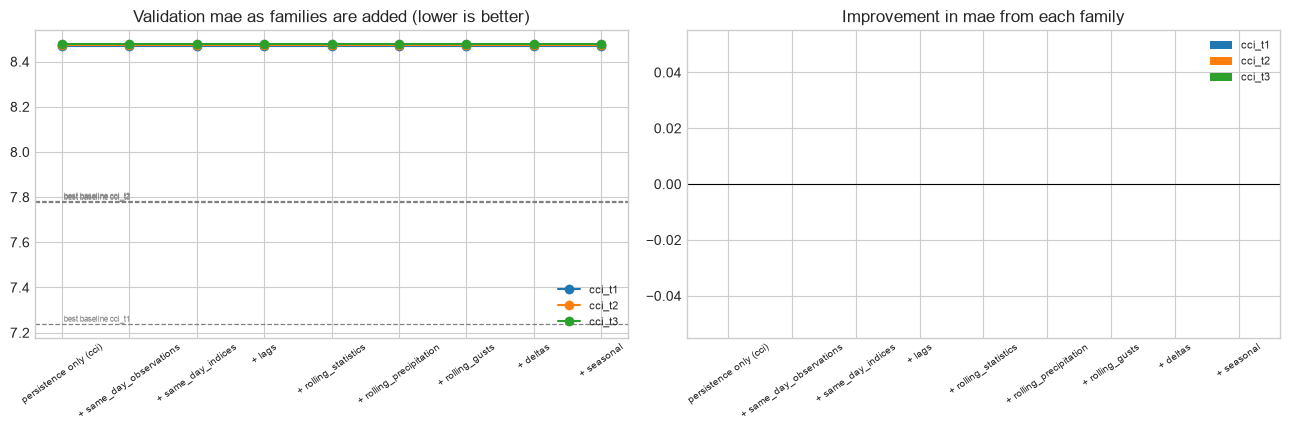

target,cci_t1,cci_t2,cci_t3,n_features
config,,,,
persistence only (cci),8.471,8.475,8.476,1
+ same_day_observations,8.471,8.475,8.476,6
+ same_day_indices,8.471,8.475,8.476,17
+ lags,8.471,8.475,8.476,49
+ rolling_statistics,8.471,8.475,8.476,89
+ rolling_precipitation,8.471,8.475,8.476,93
+ rolling_gusts,8.471,8.475,8.476,97
+ deltas,8.471,8.475,8.476,103
+ seasonal,8.471,8.475,8.476,105


In [15]:
ablation = exp.run_ablation()
plt.show()
ablation

---
## 5. Cross-validated results

The chosen configuration is cross-validated again and compared with every baseline, all on the same folds. `gain_of_model` is positive when the model beats that row. The plot shows the **out-of-fold predictions**: every validation year predicted by a model that never saw it.

`pred_std` is shown next to the error metrics. A spread far below the observed spread means the
model is playing safe by predicting close to the average, which can give a respectable MAE while
missing exactly the uncomfortable days users care about. Expect error to grow with the horizon.

In [16]:
exp.assess()

[cci_dummy_mean] assess cci_t1: default mean mae = 8.4711 (best baseline 7.2395)


[cci_dummy_mean] assess cci_t2: default mean mae = 8.4755 (best baseline 7.7842)
[cci_dummy_mean] assess cci_t3: default mean mae = 8.4758 (best baseline 7.7788)


mae   rmse     r2  pred_std  train_mae  gain_of_model
target model                                                              
cci_t1 climatology 7.789 10.406  0.002     3.712        NaN         -0.683
       default     8.471 10.994 -0.112     0.000      7.693         -0.000
       persistence 7.240  9.614  0.142    10.407        NaN         -1.232
cci_t2 climatology 7.784 10.401  0.003     3.700        NaN         -0.691
       default     8.475 10.998 -0.111     0.000      7.693         -0.000
       persistence 9.069 11.788 -0.295    10.407        NaN          0.594
cci_t3 climatology 7.779 10.398  0.004     3.701        NaN         -0.697
       default     8.476 10.996 -0.110     0.000      7.693         -0.000
       persistence 9.917 12.783 -0.529    10.407        NaN          1.441

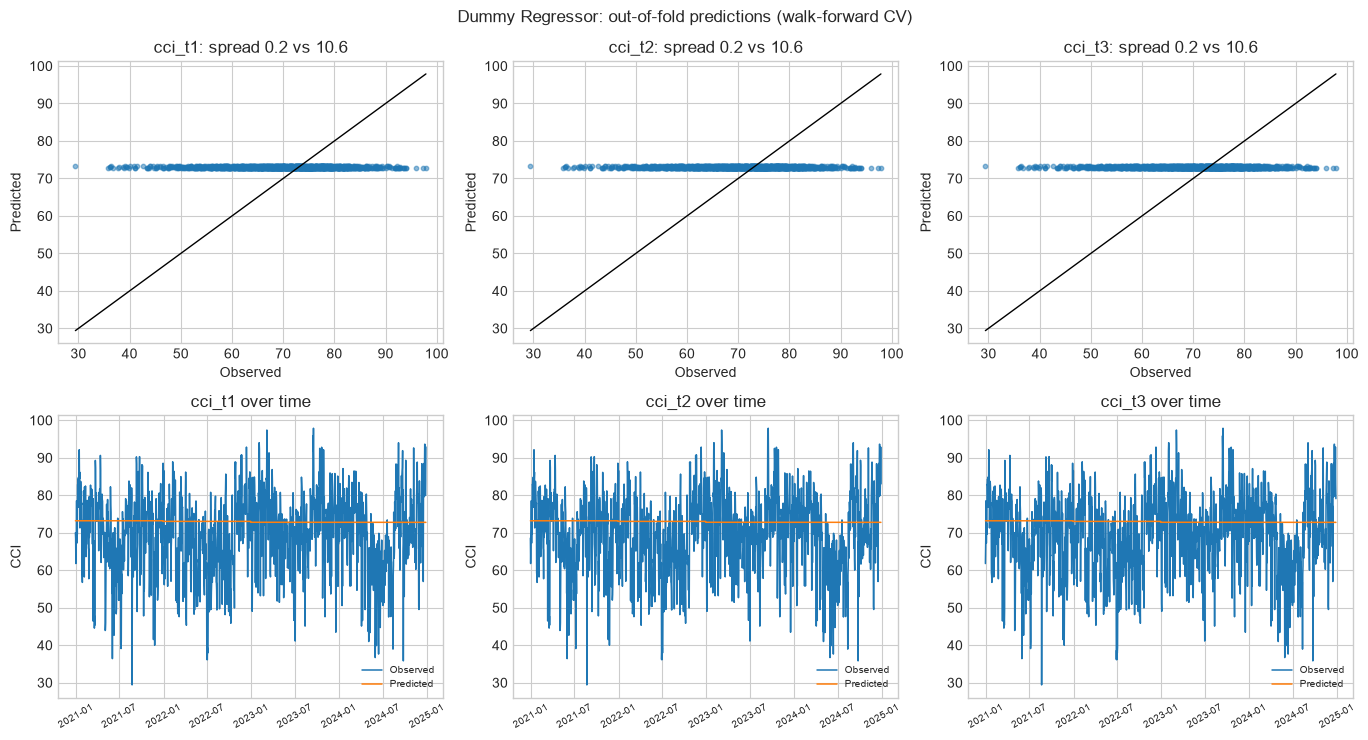

In [17]:
exp.plot_validation()
plt.show()

---
## 6. Feature importance

A dummy model ignores the features, so there is no importance to report.

> Importance is measured on the last fold's model and validation year (2024). Correlated features share importance, so the ablation in section 4 is the better guide to what can be removed.

In [18]:
family_importance = exp.importance()
plt.show()
family_importance

[cci_dummy_mean] computing feature importance (permutation importance can take a while)
No feature importance: this estimator ignores the features.


---
## 7. Generalisation check

Mean training and validation scores over the folds. A small gap means the model
generalises; a large gap means it memorises the training years.

In [19]:
exp.generalisation()

,train_mae,validation_mae,validation_minus_train
target,,,
cci_t1,7.693,8.471,0.778
cci_t2,7.693,8.475,0.783
cci_t3,7.693,8.476,0.783


---
## 8. Save the experiment bundle

The chosen configuration is refitted on **all development data** and saved to
`models/comfort_climate/experiments/cci_dummy_mean/`:

| File | Contents |
|:--|:--|
| `cci_dummy_mean_h<horizon>.joblib` | The model, one per horizon |
| `metadata.json` | Settings, features, importance and the cross-validated scores |
| `manifest.json` | File list and the feature column order |
| `spec.joblib` | The specification and tuned settings, which the comparison notebook uses to rebuild this experiment |

In [20]:
exp.export()

[cci_dummy_mean] final fit cci_t1: 9,099 rows, 105 features
[cci_dummy_mean] final fit cci_t2: 9,099 rows, 105 features
[cci_dummy_mean] final fit cci_t3: 9,099 rows, 105 features
Saved bundle: models/comfort_climate/experiments/cci_dummy_mean


PosixPath('/Users/juanvargas/UTS/3rd Semester/AdvanceML/Assignment_2/36120-26SP-AT2-25945320-experiments/models/comfort_climate/experiments/cci_dummy_mean')

---
## 9. Conclusions

- **This is the floor, not the bar.** Persistence and climatology both use information and should
  beat it comfortably; the size of those gaps (section 5) measures what current weather and
  the calendar are each worth.
- **`pred_std` is zero by construction.** This model *is* the "retreat to the average" that
  `pred_std` detects in the other notebooks, so it calibrates how to read that number.
- **Mean, not median.** The mean minimises squared error, while MAE is minimised by the median.
  Because CCI is skewed by poor-comfort days, a median would score slightly better on MAE; it is
  not used, so the floor stays the simplest possible forecast.
- **Ablation.** Every feature set scores identically (section 4), confirming the model
  ignores `X`.

> A null model is never shortlisted: it has nothing to tune and exists only as the floor.

> The test split has still not been used. It is scored exactly once, in the `cci_comparison` notebook, after the champion has been chosen.